# Notebook 03 — SHAP explainability (J26-IT-388, Component 4)

**Research task:** Explain the _existing, frozen_ Dreaddit TF-IDF + Logistic Regression classifier. No fitting or tuning of the prediction model occurs here.

**Interpretation:** Binary class `1` = **stress-related text**. SHAP values from the linear classifier are contributions to the **decision function (log-odds)**, **not percentage-point changes in probability**. The model is not a clinical risk predictor.

**Data hygiene:** Original train/test remain unchanged. Training samples build the SHAP reference background; held-out test samples are used for explanations and diagnostics only. Test labels are used to select error-analysis examples, not to optimize the model. No raw social-media text is exported into evidence files. User authorization and dataset license restrictions still apply.

**PP1 evidence:** Global token importance, class-specific examples, local token contributions, exact log-odds reconstruction, stability under background sampling, runtime measurements, metadata and figures.


## 0. Install dependencies (run once in the VS Code `.venv` terminal)

```cmd
python -m pip install "shap>=0.46,<0.52" "scikit-learn>=1.5,<1.9" pandas numpy scipy matplotlib joblib ipykernel jupyter
```

Avoid replacing the saved Notebook 02 model with a retrained copy. Scikit-learn pickle/joblib models should only be loaded from trusted sources, ideally with the same package versions used when saving them.


In [1]:
from pathlib import Path
import json, time, platform, sys, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import joblib
import shap
import sklearn
from scipy.special import expit
from IPython.display import display

RANDOM_STATE = 42
N_BACKGROUND = 128
N_EXPLAIN = 120
N_STABILITY_BACKGROUNDS = 3
N_STABILITY_SAMPLES = 20
N_TOP_GLOBAL = 20
TOP_LOCAL = 12
rng = np.random.default_rng(RANDOM_STATE)

here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / 'models' / 'dreaddit_tfidf_logreg.joblib').exists() and (p / 'data' / 'raw' / 'dreaddit' / 'dreaddit-test.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook from the repository root/notebooks folder. Missing saved model or Dreaddit CSVs.')
TRAIN_PATH = ROOT / 'data/raw/dreaddit/dreaddit-train.csv'
TEST_PATH = ROOT / 'data/raw/dreaddit/dreaddit-test.csv'
MODEL_PATH = ROOT / 'models/dreaddit_tfidf_logreg.joblib'
METRICS_DIR = ROOT / 'experiments/metrics/notebook03'
FIG_DIR = ROOT / 'experiments/figures/notebook03'
METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)
print('SHAP:', shap.__version__, '| scikit-learn:', sklearn.__version__)

Project root: E:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388
SHAP: 0.51.0 | scikit-learn: 1.8.0


## 1. Load and verify the _saved_ classifier and original CSVs


In [2]:
# Only load trusted local artifacts generated by Notebook 02.
pipeline = joblib.load(MODEL_PATH)
assert list(pipeline.named_steps) == ['tfidf', 'model'], 'Unexpected pipeline layout; inspect before proceeding.'
vectorizer = pipeline.named_steps['tfidf']
classifier = pipeline.named_steps['model']
assert isinstance(classifier, sklearn.linear_model.LogisticRegression)
assert classifier.classes_.tolist() == [0, 1]
assert classifier.coef_.shape[0] == 1, 'This notebook expects binary logistic regression.'
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
assert {'text','label'}.issubset(train.columns) and {'text','label'}.issubset(test.columns)
assert train['text'].notna().all() and test['text'].notna().all()
train_text = train['text'].astype(str).tolist()
test_text = test['text'].astype(str).tolist()
assert len(test_text)==715, f'Unexpected original test length: {len(test_text)}'
feature_names = np.asarray(vectorizer.get_feature_names_out())
assert len(feature_names)==classifier.coef_.shape[1]
print('Saved model:', MODEL_PATH.name, '| training rows:',len(train),'| held-out rows:',len(test))
print('TF-IDF dimensions:',len(feature_names),'| classes:',classifier.classes_.tolist())
print('Model unchanged; no .fit calls are used anywhere in this notebook.')

e:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388\.venv\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
e:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388\.venv\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
e:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388\.venv\Lib\site-packages\sklearn\base.py:463: Incons

Saved model: dreaddit_tfidf_logreg.joblib | training rows: 2838 | held-out rows: 715
TF-IDF dimensions: 20000 | classes: [0, 1]
Model unchanged; no .fit calls are used anywhere in this notebook.


## 2. Select reproducible SHAP background and held-out explanation samples

The background is sampled **only from training observations** and defines the reference average log-odds. A stratified-by-true-label sample is used for explanatory coverage (this selection does not alter the predictor).


In [3]:
def stratified_indices(labels, requested, seed):
    labels = np.asarray(labels)
    groups = np.unique(labels)
    rs = np.random.default_rng(seed)
    allocation = [requested // len(groups) + (i < requested % len(groups)) for i in range(len(groups))]
    chosen=[]
    for g, count in zip(groups,allocation):
        pool=np.flatnonzero(labels==g)
        if count>len(pool):raise ValueError('Too few samples for stratification')
        chosen.extend(rs.choice(pool,size=count,replace=False).tolist())
    return np.asarray(sorted(chosen),dtype=int)

background_idx = stratified_indices(train['label'],N_BACKGROUND,RANDOM_STATE)
explain_idx = stratified_indices(test['label'],N_EXPLAIN,RANDOM_STATE+1)
X_background = vectorizer.transform([train_text[i] for i in background_idx])
X_explain = vectorizer.transform([test_text[i] for i in explain_idx])
assert sp.issparse(X_background) and sp.issparse(X_explain)
assert X_background.shape[1]==X_explain.shape[1]
print('Background:',X_background.shape,'(training only), explained:',X_explain.shape,'(test only)')
print('Explained label distribution:',test.iloc[explain_idx]['label'].value_counts().to_dict())

Background: (128, 20000) (training only), explained: (120, 20000) (test only)
Explained label distribution: {0: 60, 1: 60}


## 3. Compute SHAP using a linear explainer in raw log-odds space

For a binary linear logistic regression, `decision_function` is the logit of `predict_proba(... )[:,1]`. For an independent-feature masker, SHAP sums should reconstruct the decision score. The TF-IDF features are correlated in practice, so feature attributions depend on the chosen background/masking assumption.


In [4]:
start=time.perf_counter()
explainer=shap.LinearExplainer(classifier, shap.maskers.Independent(X_background))
explainer_initialization_seconds=time.perf_counter()-start
start=time.perf_counter()
sv=explainer(X_explain)
explanation_seconds=time.perf_counter()-start
values=sv.values
if sp.issparse(values): values=values.toarray()
values=np.asarray(values)
assert values.shape==X_explain.shape, (values.shape,X_explain.shape)
base_values=np.asarray(sv.base_values).reshape(-1)
if base_values.size==1:base_values=np.repeat(base_values,len(explain_idx))
assert base_values.size==len(explain_idx)
print('SHAP value matrix:',values.shape)
print(f'Initialization: {explainer_initialization_seconds:.4f}s; batch explanation: {explanation_seconds:.4f}s')

SHAP value matrix: (120, 20000)
Initialization: 0.0067s; batch explanation: 0.0889s


## 4. Exactness checks: additivity, log-odds and probability consistency


In [5]:
decisions=classifier.decision_function(X_explain)
probabilities=pipeline.predict_proba([test_text[i] for i in explain_idx])[:,1]
reconstructed=base_values+values.sum(axis=1)
residual=decisions-reconstructed
prob_reconstructed=expit(reconstructed)
prob_residual=probabilities-prob_reconstructed
check_table=pd.DataFrame({
    'original_test_row':explain_idx,'true_label':test.iloc[explain_idx]['label'].to_numpy(),
    'predicted_label':pipeline.predict([test_text[i] for i in explain_idx]),
    'predicted_probability':probabilities,'model_log_odds':decisions,
    'shap_base_log_odds':base_values,'sum_shap_log_odds':values.sum(axis=1),
    'reconstructed_log_odds':reconstructed,'absolute_log_odds_error':np.abs(residual),
    'absolute_probability_error':np.abs(prob_residual)
})
display(check_table.head(8).round(6))
max_logit_error=float(np.max(np.abs(residual)))
max_probability_error=float(np.max(np.abs(prob_residual)))
assert max_logit_error<1e-6, f'Failed SHAP additivity: {max_logit_error}'
assert max_probability_error<1e-6, f'Failed sigmoid probability consistency: {max_probability_error}'
print('MAX SHAP reconstruction error (log-odds):',max_logit_error)
print('MAX reconstructed probability discrepancy:',max_probability_error)
check_table.to_csv(METRICS_DIR/'shap_additivity_checks.csv',index=False)

,original_test_row,true_label,predicted_label,predicted_probability,model_log_odds,shap_base_log_odds,sum_shap_log_odds,reconstructed_log_odds,absolute_log_odds_error,absolute_probability_error
0,1,0,0,0.450695,-0.197863,0.068497,-0.266361,-0.197863,0.0,0.0
1,6,0,0,0.345833,-0.637406,0.068497,-0.705904,-0.637406,0.0,0.0
2,9,0,0,0.373382,-0.517735,0.068497,-0.586232,-0.517735,0.0,0.0
3,10,1,1,0.584680,0.342013,0.068497,0.273516,0.342013,0.0,0.0
4,22,0,1,0.634791,0.552827,0.068497,0.484330,0.552827,0.0,0.0
5,25,0,0,0.371590,-0.525403,0.068497,-0.593900,-0.525403,0.0,0.0
6,28,0,0,0.242250,-1.140384,0.068497,-1.208882,-1.140384,0.0,0.0
7,53,1,0,0.418586,-0.328581,0.068497,-0.397079,-0.328581,0.0,0.0


MAX SHAP reconstruction error (log-odds): 1.7763568394002505e-15
MAX reconstructed probability discrepancy: 3.3306690738754696e-16


## 5. Global feature importance

Rank terms by mean absolute SHAP contribution over the selected held-out examples. This describes the current **provisional model** and sampled explanation set, not causal effects on mental health.


,feature,mean_abs_shap_log_odds,mean_signed_shap_log_odds
0,me,0.11109,0.01298
1,you,0.08886,0.00602
2,my,0.08234,-0.01252
3,we,0.05879,0.00306
4,and,0.04682,0.00740
5,she,0.04637,-0.00670
6,her,0.04419,0.00302
7,just,0.04288,-0.00972
8,do,0.04231,0.00031
9,feel,0.03869,0.00509


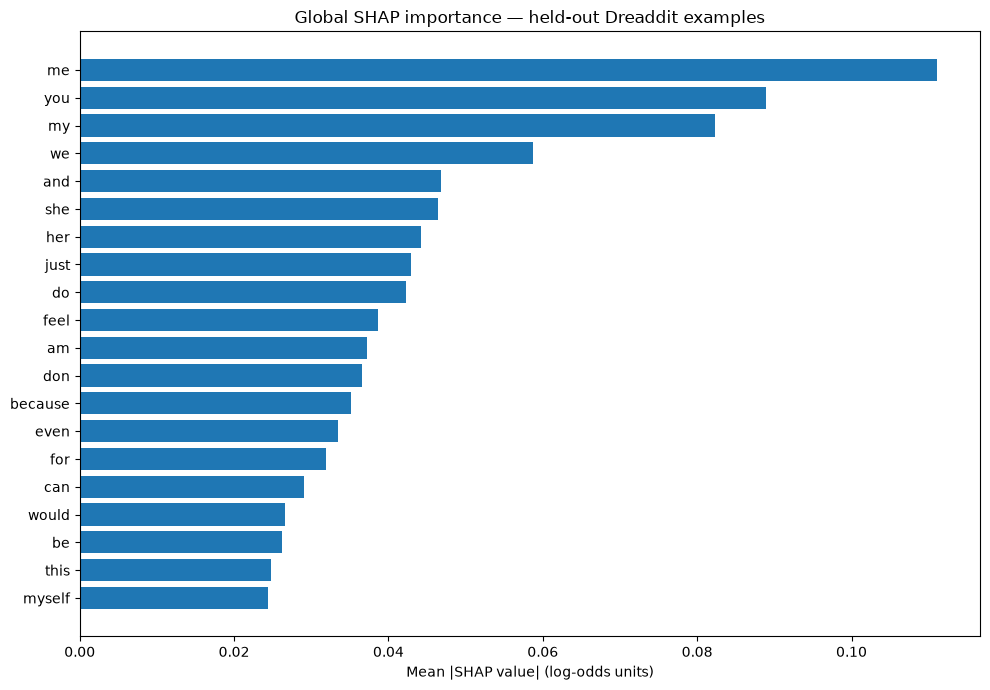

In [6]:
mean_abs=np.mean(np.abs(values),axis=0)
mean_signed=np.mean(values,axis=0)
global_df=pd.DataFrame({'feature':feature_names,'mean_abs_shap_log_odds':mean_abs,'mean_signed_shap_log_odds':mean_signed})
global_df=global_df.sort_values('mean_abs_shap_log_odds',ascending=False).reset_index(drop=True)
assert global_df['mean_abs_shap_log_odds'].is_monotonic_decreasing
global_df.to_csv(METRICS_DIR/'global_shap_importance.csv',index=False)
display(global_df.head(20).round(5))
show=global_df.head(N_TOP_GLOBAL).iloc[::-1]
fig,ax=plt.subplots(figsize=(10,7))
ax.barh(show['feature'],show['mean_abs_shap_log_odds'])
ax.set_xlabel('Mean |SHAP value| (log-odds units)')
ax.set_title('Global SHAP importance — held-out Dreaddit examples')
fig.tight_layout();fig.savefig(FIG_DIR/'01_global_shap_importance.png',dpi=180,bbox_inches='tight');plt.show()

## 6. Positive and negative local explanations

Values above zero push the **stress-related class (1)** log-odds up relative to the baseline; negative values push it down. A positive contribution does **not** automatically imply high stress, and it does not represent an additive probability increase. The plots show contributions for a few test examples, with no raw text exported.


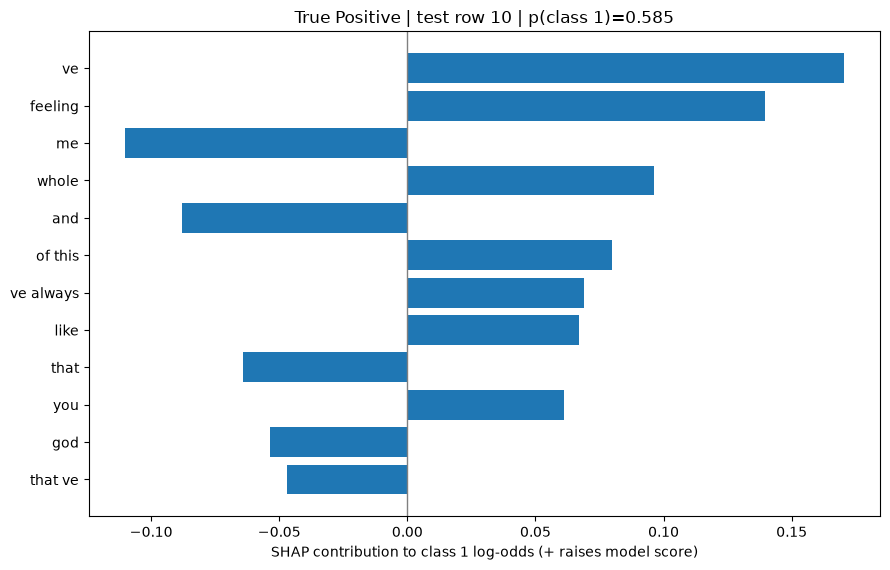

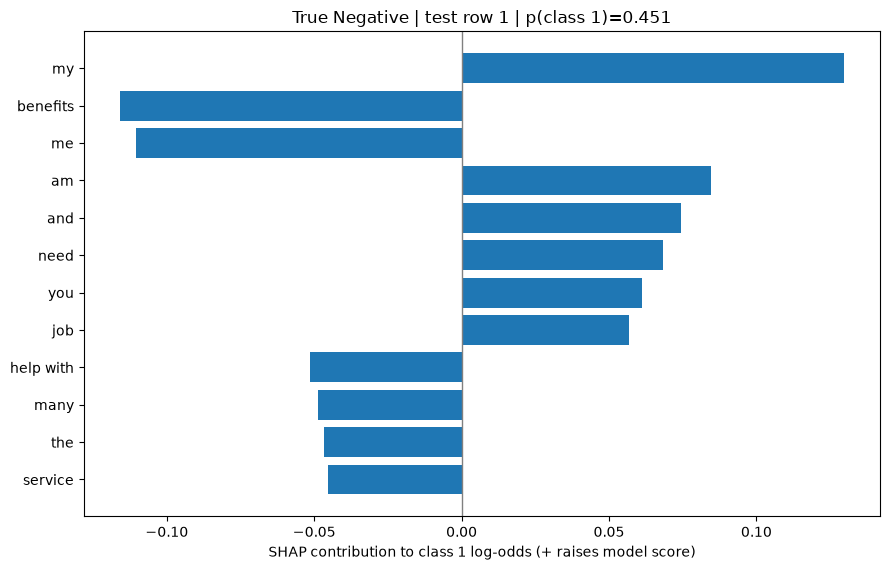

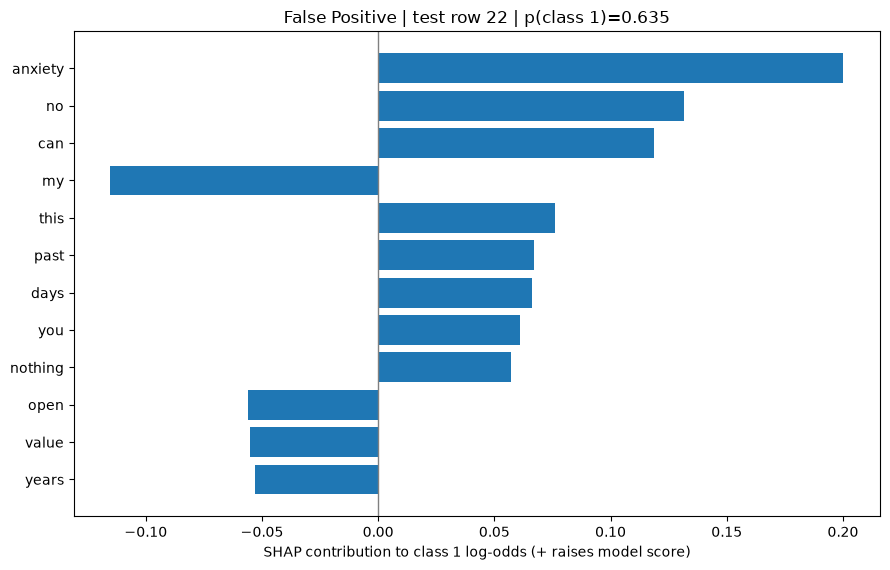

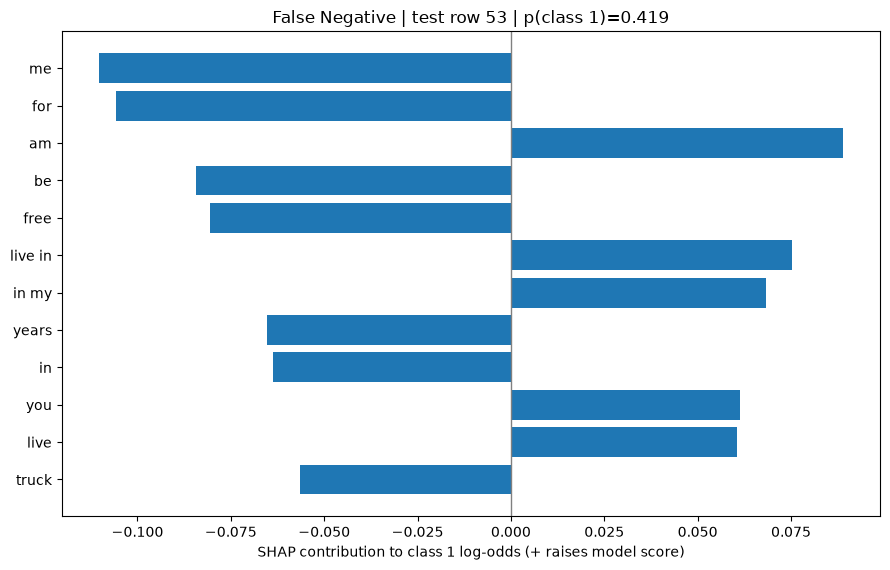

,case,num_top_terms,test_row,p_stress
0,false_negative,12,53,0.418586
1,false_positive,12,22,0.634791
2,true_negative,12,1,0.450695
3,true_positive,12,10,0.584680


In [7]:
# Pick examples based on frozen predictions. This is explanation-case selection, not model tuning.
pred_labels=check_table['predicted_label'].to_numpy()
true_labels=check_table['true_label'].to_numpy()
case_specs=[('true_positive',np.flatnonzero((pred_labels==1)&(true_labels==1))),
            ('true_negative',np.flatnonzero((pred_labels==0)&(true_labels==0))),
            ('false_positive',np.flatnonzero((pred_labels==1)&(true_labels==0))),
            ('false_negative',np.flatnonzero((pred_labels==0)&(true_labels==1)))]
local_rows=[]
for name,candidates in case_specs:
    if not len(candidates):continue
    i=int(candidates[0])
    contrib=values[i]
    order=np.argsort(np.abs(contrib))[-TOP_LOCAL:]
    terms=feature_names[order]
    vals=contrib[order]
    local_rows.extend([{'case':name,'original_test_row':int(explain_idx[i]),'term':str(term),
                        'shap_log_odds':float(v),'prediction_probability':float(probabilities[i])}
                       for term,v in zip(terms,vals)])
    fig,ax=plt.subplots(figsize=(9,5.8))
    y=np.arange(len(order));bars=ax.barh(y,vals)
    ax.set_yticks(y,labels=terms);ax.axvline(0,color='gray',linewidth=1)
    ax.set_xlabel('SHAP contribution to class 1 log-odds (+ raises model score)')
    ax.set_title(f'{name.replace("_"," ").title()} | test row {explain_idx[i]} | p(class 1)={probabilities[i]:.3f}')
    fig.tight_layout();fig.savefig(FIG_DIR/f'02_local_{name}.png',dpi=180,bbox_inches='tight');plt.show()
local_df=pd.DataFrame(local_rows)
local_df.to_csv(METRICS_DIR/'local_shap_examples.csv',index=False)
display(local_df.groupby('case',as_index=False).agg(num_top_terms=('term','count'),test_row=('original_test_row','first'),p_stress=('prediction_probability','first')))

## 7. Model coefficient direction versus SHAP direction

For a linear model, nonzero TF-IDF coefficients determine the direct effect of increasing a term feature on the decision score. SHAP contributions also reflect the chosen reference feature level. Do not treat signed global means as causal statements.


In [8]:
coef=classifier.coef_[0]
coef_df=pd.DataFrame({'feature':feature_names,'coefficient_log_odds_per_tfidf_unit':coef}).sort_values('coefficient_log_odds_per_tfidf_unit')
coef_df.to_csv(METRICS_DIR/'model_coefficients_reference.csv',index=False)
print('Most negative (class 0 direction):')
display(coef_df.head(10).round(4))
print('Most positive (class 1 direction):')
display(coef_df.tail(10).iloc[::-1].round(4))

Most negative (class 0 direction):


,feature,coefficient_log_odds_per_tfidf_unit
19848,you,-2.7313
18899,we,-1.8067
19950,your,-1.6520
18352,url,-1.5097
14882,she,-1.4483
10031,met,-1.4048
7337,her,-1.3828
10204,more,-1.2205
5841,for,-1.2171
19677,would,-1.1368


Most positive (class 1 direction):


,feature,coefficient_log_odds_per_tfidf_unit
9786,me,3.5556
10344,my,2.7585
5563,feel,2.2363
2098,because,2.0112
5216,even,1.9736
8800,just,1.9703
655,am,1.8946
4816,don,1.7667
4669,do,1.7585
792,and,1.7144


## 8. Consistency and reference-background sensitivity

We compare exact repeat runs on an unchanged explainer, then vary training-only background subsets. Shifting the reference distribution can shift attributions while preserving additivity; this is an important limitation to report. This is **not** a user study of explanation usefulness.


In [9]:
small_X=X_explain[:N_STABILITY_SAMPLES]
repeat_start=time.perf_counter()
repeat_values=np.asarray(explainer(small_X).values)
if sp.issparse(repeat_values): repeat_values=repeat_values.toarray()
repeat_max_diff=float(np.max(np.abs(repeat_values-values[:N_STABILITY_SAMPLES])))
assert repeat_max_diff<1e-8, repeat_max_diff

reference_ranks=[]; baseline_logits=[]; run_seconds=[]
for j in range(N_STABILITY_BACKGROUNDS):
    new_idx=stratified_indices(train['label'],N_BACKGROUND,RANDOM_STATE+100+j)
    X_bg=vectorizer.transform([train_text[k] for k in new_idx])
    t=time.perf_counter()
    alt_exp=shap.LinearExplainer(classifier,shap.maskers.Independent(X_bg))
    alt_sv=alt_exp(small_X)
    alt_values=alt_sv.values.toarray() if sp.issparse(alt_sv.values) else np.asarray(alt_sv.values)
    run_seconds.append(time.perf_counter()-t)
    reference_ranks.append(np.argsort(np.mean(np.abs(alt_values),axis=0))[-20:])
    baseline_logits.append(float(np.asarray(alt_sv.base_values).reshape(-1)[0]))
sets=[set(a.tolist()) for a in reference_ranks]
pairwise_jaccard=[]
for i in range(len(sets)):
    for j in range(i+1,len(sets)):
        pairwise_jaccard.append(len(sets[i]&sets[j])/len(sets[i]|sets[j]))
stability={'repeat_max_abs_difference':repeat_max_diff,
           'background_top20_pairwise_jaccard':pairwise_jaccard,
           'background_top20_mean_jaccard':float(np.mean(pairwise_jaccard)),
           'background_base_log_odds':baseline_logits,
           'background_runtimes_seconds':run_seconds,
           'interpretation':'Background-dependent feature attributions; top-term overlap is descriptive, not a quality ground truth.'}
(METRICS_DIR/'shap_consistency_background_sensitivity.json').write_text(json.dumps(stability,indent=2),encoding='utf-8')
print(json.dumps(stability,indent=2))

{
  "repeat_max_abs_difference": 0.0,
  "background_top20_pairwise_jaccard": [
    1.0,
    1.0,
    1.0
  ],
  "background_top20_mean_jaccard": 1.0,
  "background_base_log_odds": [
    0.11491157839688881,
    -0.00903343459056738,
    -0.05213398566315053
  ],
  "background_runtimes_seconds": [
    0.040445599996019155,
    0.03596099998685531,
    0.04093339998507872
  ],
  "interpretation": "Background-dependent feature attributions; top-term overlap is descriptive, not a quality ground truth."
}


## 9. Latency and performance (illustrative local-machine measurements)

Timing depends on hardware, library versions, matrix sparsity and background size. This is not proof of real-time deployment latency. Separate the vectorizer, explainer initialization, and explanation stages.


In [10]:
t=time.perf_counter()
for idx in explain_idx: _=vectorizer.transform([test_text[idx]])
vectorization_seconds=time.perf_counter()-t
latency={
 'n_explained':len(explain_idx),'n_background':len(background_idx),
 'vectorization_single_calls_total_seconds':vectorization_seconds,
 'vectorization_mean_per_sample_ms':1000*vectorization_seconds/len(explain_idx),
 'explainer_initialization_seconds':explainer_initialization_seconds,
 'explanation_batch_seconds':explanation_seconds,
 'mean_explanation_batch_ms_per_sample':1000*explanation_seconds/len(explain_idx),
 'warning':'Batch average is not single-request end-to-end API latency.'}
(METRICS_DIR/'shap_runtime.json').write_text(json.dumps(latency,indent=2),encoding='utf-8')
print(json.dumps(latency,indent=2))

{
  "n_explained": 120,
  "n_background": 128,
  "vectorization_single_calls_total_seconds": 0.0809616000042297,
  "vectorization_mean_per_sample_ms": 0.6746800000352474,
  "explainer_initialization_seconds": 0.00674129999242723,
  "explanation_batch_seconds": 0.08892819998436607,
  "mean_explanation_batch_ms_per_sample": 0.7410683332030507,
  "warning": "Batch average is not single-request end-to-end API latency."
}


## 10. Evidence summary and reproducibility manifest


In [11]:
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()
summary={
 'project':'J26-IT-388 Component 4', 'notebook':'03_shap_explainability',
 'created_utc':datetime.now(timezone.utc).isoformat(),
 'task':'Explain an existing binary stress-related-text classifier; no training',
 'shap_output_units':'class 1 log-odds (linear decision function)',
 'model_artifact_sha256':sha256(MODEL_PATH),
 'train_csv_sha256':sha256(TRAIN_PATH),'test_csv_sha256':sha256(TEST_PATH),
 'train_rows':len(train),'test_rows':len(test),'features':len(feature_names),
 'explained_test_rows':len(explain_idx),'reference_train_rows':len(background_idx),
 'selection_seed':RANDOM_STATE, 'max_abs_additivity_error_log_odds':max_logit_error,
 'max_abs_reconstructed_probability_error':max_probability_error,
 'mean_abs_global_top_term':global_df.iloc[0]['feature'],
 'repeat_max_abs_difference':repeat_max_diff,
 'mean_top20_jaccard_across_backgrounds':float(np.mean(pairwise_jaccard)),
 'package_versions':{'python':sys.version.split()[0],'shap':shap.__version__,
                     'sklearn':sklearn.__version__,'numpy':np.__version__,'pandas':pd.__version__},
 'limitations':['Text-only provisional classifier, not clinical mental health prediction',
                'SHAP values are model-specific associations, not causal explanations',
                'Background features may be dependent; results depend on chosen masking/reference distribution',
                'Original Dreaddit test set includes three exact text overlaps with training',
                'No human interpretability or clinical validation in this notebook']
}
(METRICS_DIR/'shap_summary.json').write_text(json.dumps(summary,indent=2,default=str),encoding='utf-8')
print('Saved results to:',METRICS_DIR)
print('Saved figures to:',FIG_DIR)
print('NO model fit, model tuning or model overwrite performed.')
print('Global top terms:');display(global_df.head(10))

Saved results to: E:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388\experiments\metrics\notebook03
Saved figures to: E:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388\experiments\figures\notebook03
NO model fit, model tuning or model overwrite performed.
Global top terms:


,feature,mean_abs_shap_log_odds,mean_signed_shap_log_odds
0,me,0.111093,0.012978
1,you,0.088864,0.006018
2,my,0.082336,-0.012522
3,we,0.058786,0.003063
4,and,0.046821,0.007398
5,she,0.046369,-0.006704
6,her,0.044194,0.003019
7,just,0.042878,-0.009722
8,do,0.042315,0.000307
9,feel,0.038687,0.005095


## PP1 presentation notes

1. **What is explained?** The saved TF-IDF + Logistic Regression model's prediction for **stress-related text**.
2. **How is SHAP computed?** A sparse linear explainer using a training-only reference sample.
3. **What do the numbers mean?** Baseline log-odds + sum of token SHAP values = model decision log-odds. Applying `sigmoid` recovers class 1 probability; **individual SHAP scores are not percentages**.
4. **How was it validated?** Numerical additivity, probability reconstruction, repeated explanations, background sensitivity and runtime.
5. **What cannot be concluded?** Causation, medical diagnosis, longitudinal risk detection, fairness or improved human understanding.
6. **What is next?** Notebook 04: LIME local explanations, then comparative explanation evaluation and adaptive scoring, without changing the held-out test to optimize performance.

**Before committing:** Some tokens might contain personal or sensitive expressions. Review `global_shap_importance.csv`, `local_shap_examples.csv`, plots and `model_coefficients_reference.csv` before publishing. The raw CSVs and model are excluded from Git by your `.gitignore`.
